<a href="https://colab.research.google.com/github/butthamza20/ECS708U-P-Fashion-MNIST-Coursework/blob/main/ECS708U_P_Fashion_MNIST_Coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0.1 Fixed data partitions

### Repository Link: https://github.com/butthamza20/ECS708U-P-Fashion-MNIST-Coursework

### Importing libraries

In [22]:
import os
import sys
import time
import random

import numpy as np
import torch
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

### Setup: random seeds and hardware

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python version:     ", sys.version.split()[0])
print("PyTorch version:    ", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("Device: GPU -", torch.cuda.get_device_name(0))
else:
    print("Device: CPU (no GPU available)")

device = "cuda" if torch.cuda.is_available() else "cpu"

Python version:      3.13.18
PyTorch version:     2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: CPU (no GPU available)


### Loading the Fashion MNIST training dataset

In [3]:
train_data = datasets.FashionMNIST(root='data', train=True, download=True, transform=transforms.ToTensor())

train_data_length = len(train_data)
print("\nTraining images:", train_data_length)
print("Classes:", train_data.classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.50MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.1MB/s]


Training images: 60000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Loading the Testing Dataset

In [4]:
test_data = datasets.FashionMNIST(root='data', train=False, download=True, transform=transforms.ToTensor())

test_data_length = len(test_data)
print("\nTest images:", test_data_length)
print("Classes:", test_data.classes)


Test images: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### Viewing example training images

Example positions: [41905, 7296, 1639, 48598, 18024, 16049]


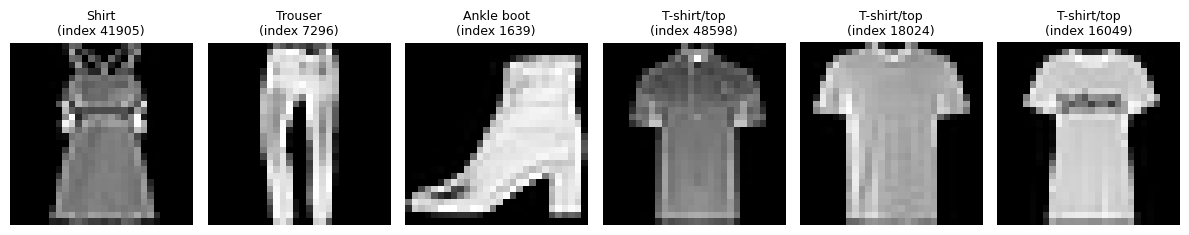

In [5]:
example_rng = random.Random(SEED)
example_positions = example_rng.sample(range(train_data_length), 6)
print("Example positions:", example_positions)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))

for i, position in enumerate(example_positions):
    image, label = train_data[position]
    axes[i].imshow(image.squeeze(), cmap='gray', interpolation='nearest')
    axes[i].set_title(f"{train_data.classes[label]}\n(index {position})", fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Creating the train/validation split (training set only)

In [6]:
all_indices = list(range(train_data_length))
all_labels = train_data.targets

split_seed = SEED
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=10000,
    stratify=all_labels,
    random_state=split_seed,
)

train_set = Subset(train_data, train_indices)
val_set = Subset(train_data, val_indices)

### Checking the split

In [7]:
overlap = set(train_indices) & set(val_indices)

print("Train size:            ", len(train_set))
print("Validation size:       ", len(val_set))
print("Images in both sets:   ", len(overlap))
print("Train class counts:    ", torch.bincount(all_labels[train_indices]).tolist())
print("Validation class counts:", torch.bincount(all_labels[val_indices]).tolist())

Train size:             50000
Validation size:        10000
Images in both sets:    0
Train class counts:     [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Validation class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


### Saving the split indices

In [8]:
os.makedirs("splits", exist_ok=True)

np.save("splits/train_indices.npy", np.array(train_indices))
np.save("splits/val_indices.npy", np.array(val_indices))

### Clustering subsets (3,000 / 1,000 / 1,000)

In [9]:
cluster_train_indices, _ = train_test_split(
    train_indices,
    train_size=3000,
    stratify=all_labels[train_indices],
    random_state=SEED,
)

In [10]:
cluster_val_indices, _ = train_test_split(
    val_indices,
    train_size=1000,
    stratify=all_labels[val_indices],
    random_state=SEED,
)

In [11]:
all_test_indices = list(range(test_data_length))

cluster_test_indices, _ = train_test_split(
    all_test_indices,
    train_size=1000,
    stratify=test_data.targets,
    random_state=SEED,
)

In [12]:
print("Clustering train size:     ", len(cluster_train_indices))
print("Clustering validation size:", len(cluster_val_indices))
print("Clustering test size:      ", len(cluster_test_indices))

print("Clustering train per class:     ", torch.bincount(all_labels[cluster_train_indices]).tolist())
print("Clustering validation per class:", torch.bincount(all_labels[cluster_val_indices]).tolist())
print("Clustering test per class:      ", torch.bincount(test_data.targets[cluster_test_indices]).tolist())

print("Clustering train all from training partition:  ", set(cluster_train_indices) <= set(train_indices))
print("Clustering validation all from validation split:", set(cluster_val_indices) <= set(val_indices))
print("Overlap between clustering train and validation:", len(set(cluster_train_indices) & set(cluster_val_indices)))

Clustering train size:      3000
Clustering validation size: 1000
Clustering test size:       1000
Clustering train per class:      [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
Clustering validation per class: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering test per class:       [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Clustering train all from training partition:   True
Clustering validation all from validation split: True
Overlap between clustering train and validation: 0


In [13]:
np.save("splits/cluster_train_indices.npy", np.array(cluster_train_indices))
np.save("splits/cluster_val_indices.npy", np.array(cluster_val_indices))
np.save("splits/cluster_test_indices.npy", np.array(cluster_test_indices))

### DataLoaders

In [14]:
size_of_batch = 64

g = torch.Generator()
_ = g.manual_seed(SEED)

train_loader = DataLoader(train_set, batch_size=size_of_batch, shuffle=True, generator=g)
val_loader = DataLoader(val_set, batch_size=size_of_batch, shuffle=False)
test_loader = DataLoader(test_data, batch_size=size_of_batch, shuffle=False)

### Checking the DataLoaders

In [ ]:
temp_images, temp_labels = next(iter(train_loader))

# Reset the generator so this check does not change the training shuffle later
_ = g.manual_seed(SEED)

print("One batch of images:", tuple(temp_images.shape))
print("One batch of labels:", tuple(temp_labels.shape))
print("Train batches:      ", len(train_loader))
print("Validation batches: ", len(val_loader))
print("Test batches:       ", len(test_loader))